In [1]:
#DMV-2 ( NO Map ) : Multiple cities

import requests
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Step 1: API details
api_key = "14c1d71a19da6eb3ee3db54d4462715b"
cities = ["Pune", "Mumbai", "Delhi", "Chennai", "Bangalore"]

url = "https://api.openweathermap.org/data/2.5/weather"

In [3]:
# Step 2: Fetch weather data
weather_data = []

for city in cities:
    params = {
        "q": city + ",IN",
        "appid": api_key,
        "units": "metric"
    }

    try:
        response = requests.get(url, params=params, timeout=10)

        if response.status_code == 200:
            data = response.json()

            weather_data.append({
                "City": data["name"],
                "Temperature": data["main"]["temp"],
                "Humidity": data["main"]["humidity"],
                "Wind_Speed": data["wind"]["speed"]
            })
        else:
            print("Error fetching", city, response.status_code)

    except requests.RequestException as e:
        print("Request failed for", city, e)

In [4]:
# Step 3: Create DataFrame
df = pd.DataFrame(weather_data)

if df.empty:
    print("No weather data retrieved. Check API key or internet.")
else:
    print("\nOriginal Weather Data:")
    print(df)

    # Step 4: Clean data
    df = df.drop_duplicates().copy()
    df = df.dropna()

    # Step 5: Analyze data
    print("\nWeather Statistics:")
    print(df.describe())

    print("\nAverage Temperature:", df["Temperature"].mean())
    print("Maximum Temperature:", df["Temperature"].max())
    print("Minimum Temperature:", df["Temperature"].min())
    print("Average Humidity:", df["Humidity"].mean())


Original Weather Data:
        City  Temperature  Humidity  Wind_Speed
0       Pune        20.64        41        1.06
1     Mumbai        27.99        47        1.54
2      Delhi        18.96        94        1.03
3    Chennai        25.60        85        2.06
4  Bengaluru        20.49        73        0.50

Weather Statistics:
       Temperature  Humidity  Wind_Speed
count     5.000000    5.0000    5.000000
mean     22.736000   68.0000    1.238000
std       3.856907   23.2379    0.588744
min      18.960000   41.0000    0.500000
25%      20.490000   47.0000    1.030000
50%      20.640000   73.0000    1.060000
75%      25.600000   85.0000    1.540000
max      27.990000   94.0000    2.060000

Average Temperature: 22.735999999999997
Maximum Temperature: 27.99
Minimum Temperature: 18.96
Average Humidity: 68.0


In [7]:
# Step 6: Save dataset
df.to_csv("weather_data.csv", index=False)

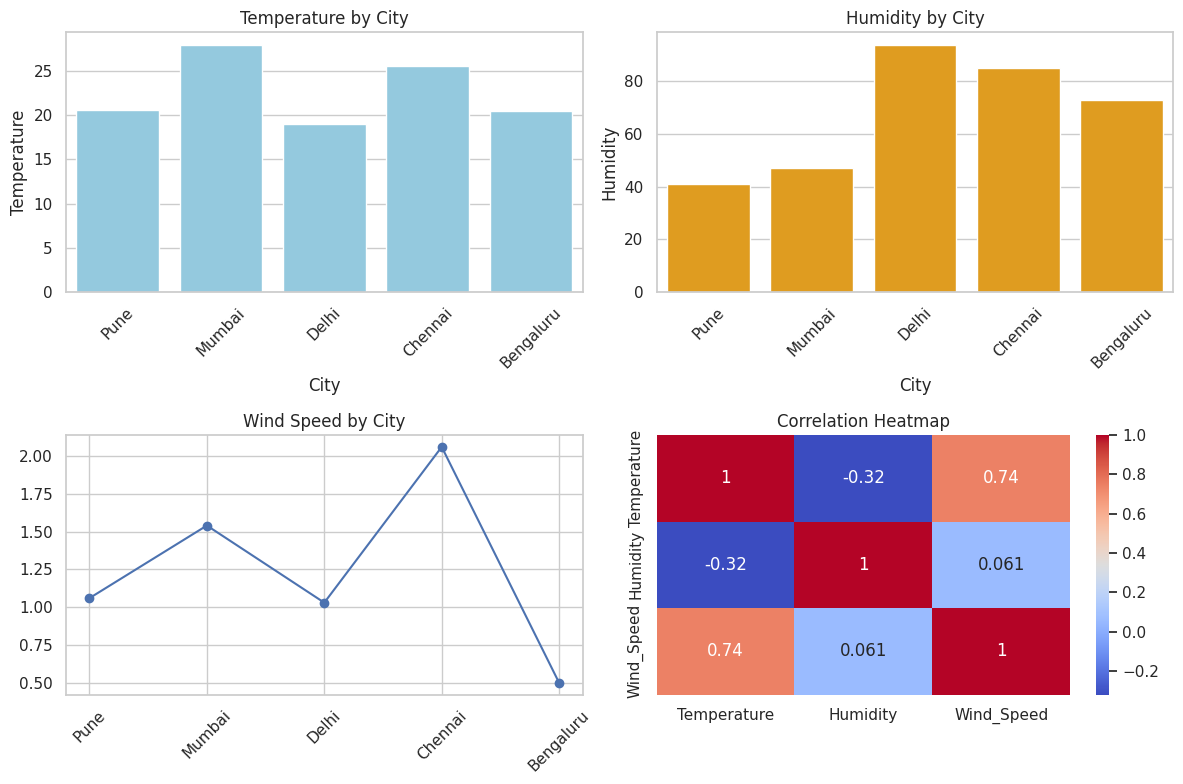

In [8]:
# Step 7: Visualization
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 8))

# Temperature Bar Chart
plt.subplot(2, 2, 1)
sns.barplot(data=df, x="City", y="Temperature",
color="skyblue")
plt.title("Temperature by City")
plt.xticks(rotation=45)

# Humidity Bar Chart
plt.subplot(2, 2, 2)
sns.barplot(data=df, x="City", y="Humidity",
color="orange")
plt.title("Humidity by City")
plt.xticks(rotation=45)

# Wind Speed Line Chart
plt.subplot(2, 2, 3)
plt.plot(df["City"], df["Wind_Speed"], marker="o")
plt.title("Wind Speed by City")
plt.xticks(rotation=45)

# Correlation Heatmap
plt.subplot(2, 2, 4)
sns.heatmap(
df[["Temperature", "Humidity", "Wind_Speed"]].corr(),
annot=True,
cmap="coolwarm"
)
plt.title("Correlation Heatmap")

plt.tight_layout()
plt.show()